# DFC2020 Dataset Exploration

## Objective

This notebook explores the DFC2020 dataset for Sentinel-1-based land use and land cover (LULC) semantic segmentation.

The objectives are to:

1. Inspect the Sentinel-1 VV/VH imagery.
2. Verify image-label correspondence.
3. Examine image dimensions, values, and missing data.
4. Analyze the available segmentation classes.
5. Visualize SAR imagery and LULC reference labels.

## Dataset Splitting Strategy

For this course project, the original DFC2020 test set will be used for training and validation, while the original DFC2020 validation set will be reserved as the final independent test set.

Only Sentinel-1 VV/VH imagery will be used as model input.

In [24]:
# Reference 3rd libraries and configuration
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

# PROJECT_ROOT must point to the cloned project directory.
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_ROOT = PROJECT_ROOT / "data" / "raw"

SPLITS = {
    "original_test": {
        "sar": DATA_ROOT / "ROIs0000_test" / "s1_0",
        "label": DATA_ROOT / "ROIs0000_test" / "dfc_0",
    },
    "original_validation": {
        "sar": DATA_ROOT / "ROIs0000_validation" / "s1_validation",
        "label": DATA_ROOT / "ROIs0000_validation" / "dfc_validation",
    },
}

for split_name, paths in SPLITS.items():
    for kind, path in paths.items():
        print(split_name, kind, path.exists(), path)

original_test sar True /Users/z.yang/playground/sar-lulc-monitor/data/raw/ROIs0000_test/s1_0
original_test label True /Users/z.yang/playground/sar-lulc-monitor/data/raw/ROIs0000_test/dfc_0
original_validation sar True /Users/z.yang/playground/sar-lulc-monitor/data/raw/ROIs0000_validation/s1_validation
original_validation label True /Users/z.yang/playground/sar-lulc-monitor/data/raw/ROIs0000_validation/dfc_validation


In [17]:
# Validate the filename and the format of iamge files
def build_pairs(sar_dir, label_dir):
    sar_files = sorted(sar_dir.glob("*.tif"))
    pairs = []
    missing = []

    for sar_path in sar_files:
        label_name = sar_path.name.replace("_s1_", "_dfc_")
        label_path = label_dir / label_name

        if label_path.exists():
            pairs.append((sar_path, label_path))
        else:
            missing.append(sar_path.name)

    return pairs, missing


all_pairs = {}

for split_name, paths in SPLITS.items():
    pairs, missing = build_pairs(
        paths["sar"],
        paths["label"]
    )

    all_pairs[split_name] = pairs

    print(f"\n{split_name}")
    print(f"Matched pairs: {len(pairs)}")
    print(f"Unmatched SAR images: {len(missing)}")

    if missing:
        print("Examples:", missing[:5])

assert any(len(v) > 0 for v in all_pairs.values()), (
    "No matching data found. Check paths and extracted filenames."
)


original_test
Matched pairs: 5128
Unmatched SAR images: 0

original_validation
Matched pairs: 986
Unmatched SAR images: 0


In [18]:
def check_pairs(sar_dir, label_dir):
    sar_files = sorted(sar_dir.glob("*.tif"))
    label_files = sorted(label_dir.glob("*.tif"))

    sar_names = {p.name for p in sar_files}
    expected_labels = {
        name.replace("_s1_", "_dfc_")
        for name in sar_names
    }
    actual_labels = {p.name for p in label_files}

    print("SAR files:", len(sar_files))
    print("Label files:", len(label_files))
    print("Missing labels:", len(expected_labels - actual_labels))
    print("Extra labels:", len(actual_labels - expected_labels))

    assert expected_labels == actual_labels

for split_name, paths in SPLITS.items():
    check_pairs(
        paths["sar"],
        paths["label"]
    )

    print()

SAR files: 5128
Label files: 5128
Missing labels: 0
Extra labels: 0

SAR files: 986
Label files: 986
Missing labels: 0
Extra labels: 0



In [19]:
# Validate the metadata
split_name = next(
    name for name, pairs in all_pairs.items() if pairs
)

sar_path, label_path = next(
    (sar, label)
    for sar, label in all_pairs["original_test"]
    if sar.name.endswith("p1216.tif")
)

with rasterio.open(sar_path) as src:
    sar = src.read().astype(np.float32)
    sar_crs = src.crs
    sar_transform = src.transform
    sar_bounds = src.bounds
    sar_descriptions = src.descriptions

with rasterio.open(label_path) as src:
    label = src.read(1)
    label_crs = src.crs
    label_transform = src.transform

print("Split:", split_name)
print("SAR:", sar_path.name)
print("Label:", label_path.name)

print("SAR shape:", sar.shape)
print("Label shape:", label.shape)

print("SAR CRS:", sar_crs)
print("SAR bounds:", sar_bounds)
print("SAR band descriptions:", sar_descriptions)

assert sar.ndim == 3 and sar.shape[0] == 2
assert label.shape == sar.shape[1:]
assert sar_crs == label_crs
assert sar_transform == label_transform

for i, band_name in enumerate(["Band 1", "Band 2"]):
    band = sar[i]
    finite = np.isfinite(band)

    print(f"\n{band_name}")
    print("Finite pixels:", finite.sum())
    if finite.any():
        print("Min:", band[finite].min())
        print("Max:", band[finite].max())
        print("Mean:", band[finite].mean())
        print("Std:", band[finite].std())

classes, counts = np.unique(
    label, return_counts=True
)

print("\nRaw label values:")
print(dict(zip(classes.tolist(), counts.tolist())))

Split: original_test
SAR: ROIs0000_test_s1_0_p1216.tif
Label: ROIs0000_test_dfc_0_p1216.tif
SAR shape: (2, 256, 256)
Label shape: (256, 256)
SAR CRS: EPSG:4326
SAR bounds: BoundingBox(left=0.0, bottom=256.0, right=256.0, top=0.0)
SAR band descriptions: (None, None)

Band 1
Finite pixels: 65536
Min: -23.940895
Max: 17.43863
Mean: -8.272058
Std: 3.9978828

Band 2
Finite pixels: 65536
Min: -31.021921
Max: 5.253128
Mean: -15.134401
Std: 3.4866836

Raw label values:
{1: 7722, 2: 3111, 4: 114, 5: 4848, 6: 9928, 7: 20021, 9: 16480, 10: 3312}


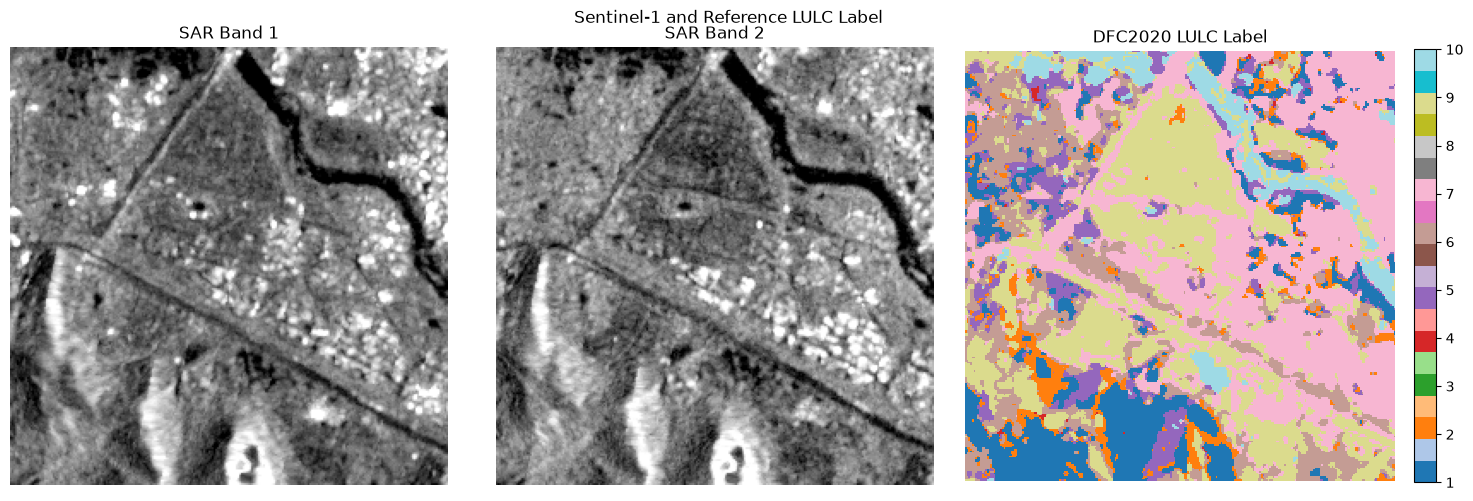

In [20]:
fig, axes = plt.subplots(
    1, 3, figsize=(15, 5)
)

for i, name in enumerate(["SAR Band 1", "SAR Band 2"]):
    band = sar[i]
    valid = band[np.isfinite(band)]

    vmin, vmax = np.percentile(valid, [2, 98])

    axes[i].imshow(
        band, cmap="gray",
        vmin=vmin, vmax=vmax
    )
    axes[i].set_title(name)
    axes[i].axis("off")

im = axes[2].imshow(
    label,
    cmap="tab20",
    interpolation="nearest"
)

axes[2].set_title("DFC2020 LULC Label")
axes[2].axis("off")

fig.colorbar(
    im, ax=axes[2],
    fraction=0.046,
    pad=0.04
)

plt.suptitle("Sentinel-1 and Reference LULC Label")
plt.tight_layout()
plt.show()

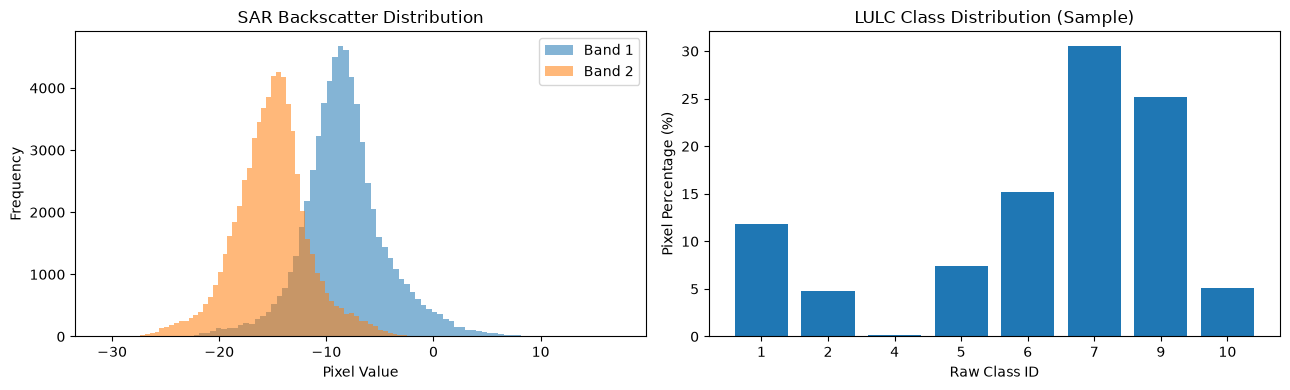

In [21]:
fig, axes = plt.subplots(
    1, 2, figsize=(13, 4)
)

for i, name in enumerate(["Band 1", "Band 2"]):
    values = sar[i]
    values = values[np.isfinite(values)]

    axes[0].hist(
        values, bins=80,
        alpha=0.55, label=name
    )

axes[0].set_title("SAR Backscatter Distribution")
axes[0].set_xlabel("Pixel Value")
axes[0].set_ylabel("Frequency")
axes[0].legend()

classes, counts = np.unique(
    label, return_counts=True
)

axes[1].bar(
    classes.astype(str),
    counts / counts.sum() * 100
)

axes[1].set_title("LULC Class Distribution (Sample)")
axes[1].set_xlabel("Raw Class ID")
axes[1].set_ylabel("Pixel Percentage (%)")

plt.tight_layout()
plt.show()


original_test


,class_id,pixels,percentage
0,1,86183010,25.644469
1,2,19916196,5.926229
2,4,34044365,10.130183
3,5,7036240,2.093692
4,6,65659277,19.537462
5,7,36050754,10.727201
6,9,8761765,2.607136
7,10,78417001,23.333629


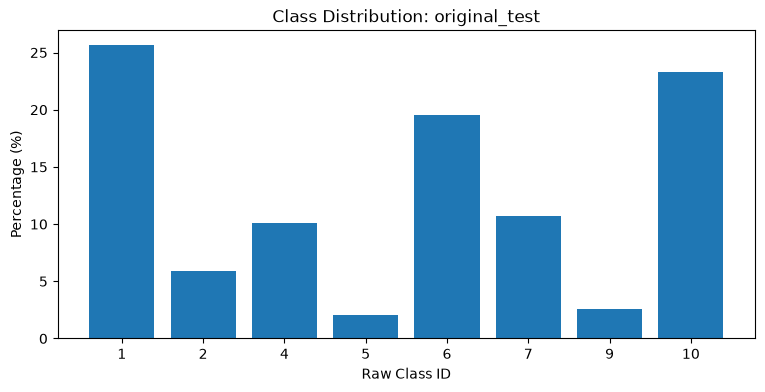


original_validation


,class_id,pixels,percentage
0,1,5904112,9.136876
1,2,3353501,5.189692
2,4,7655859,11.847783
3,5,11272496,17.444690
4,6,8405224,13.007458
5,7,3517590,5.443627
6,9,1887823,2.921490
7,10,22621891,35.008384


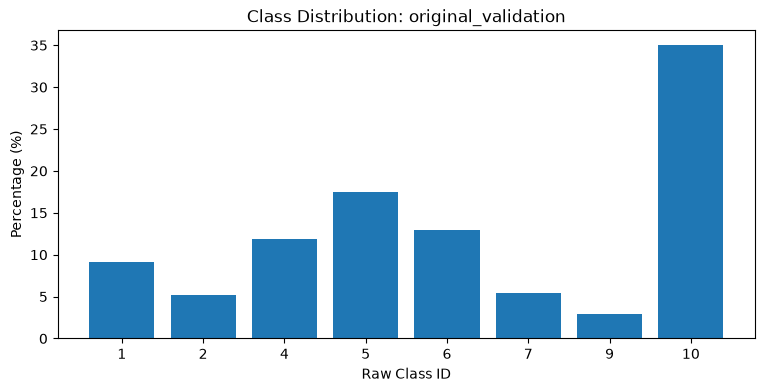

In [22]:
from collections import Counter

def count_dataset_classes(pairs):
    counts = Counter()

    for _, label_path in pairs:
        with rasterio.open(label_path) as src:
            label_array = src.read(1)

        values, frequencies = np.unique(
            label_array, return_counts=True
        )

        counts.update(
            dict(zip(values.tolist(), frequencies.tolist()))
        )

    return counts


for split_name, pairs in all_pairs.items():
    counts = count_dataset_classes(pairs)
    total = sum(counts.values())

    df = pd.DataFrame([
        {
            "class_id": class_id,
            "pixels": n,
            "percentage": n / total * 100
        }
        for class_id, n in sorted(counts.items())
    ])

    print(f"\n{split_name}")
    display(df)

    plt.figure(figsize=(9, 4))
    plt.bar(
        df["class_id"].astype(str),
        df["percentage"]
    )
    plt.title(f"Class Distribution: {split_name}")
    plt.xlabel("Raw Class ID")
    plt.ylabel("Percentage (%)")
    plt.show()

In [23]:
# Automatically search for samples with richer categories
def find_diverse_sample(pairs, max_scan=300):
    best_pair = None
    best_score = (-1, -1.0)

    for sar_path, label_path in pairs[:max_scan]:
        with rasterio.open(label_path) as src:
            labels = src.read(1)

        _, counts = np.unique(
            labels, return_counts=True
        )

        proportions = counts / counts.sum()

        entropy = -np.sum(
            proportions * np.log2(proportions)
        )

        score = (len(counts), entropy)

        if score > best_score:
            best_pair = (sar_path, label_path)
            best_score = score

    return best_pair, best_score


selected_pair, score = find_diverse_sample(
    all_pairs["original_test"]
)

print("Selected sample:", selected_pair)
print("Class count:", score[0])
print("Entropy:", score[1])

Selected sample: (PosixPath('/Users/z.yang/playground/sar-lulc-monitor/data/raw/ROIs0000_test/s1_0/ROIs0000_test_s1_0_p1216.tif'), PosixPath('/Users/z.yang/playground/sar-lulc-monitor/data/raw/ROIs0000_test/dfc_0/ROIs0000_test_dfc_0_p1216.tif'))
Class count: 8
Entropy: 2.519648626186307


## Preliminary Observations

### Data Integrity

- The original DFC2020 test set contains **5,128 matched Sentinel-1 and LULC label pairs**, while the original validation set contains **986 matched pairs**. No unmatched Sentinel-1 files were found.
- The inspected Sentinel-1 image contains two bands with a shape of `(2, 256, 256)`, and its corresponding segmentation label has a shape of `(256, 256)`. Their recorded CRS and affine transforms are consistent.
- The inspected SAR image contains no NaN or infinite values.
- Although the files report `EPSG:4326`, the recorded bounds correspond to pixel coordinates rather than plausible geographic coordinates. The available georeferencing metadata should therefore not be interpreted as reliable geographic locations.

### SAR Characteristics

- The inspected SAR bands have mean values of approximately **−19.08** and **−26.99**, respectively, with standard deviations of **1.29** and **2.05**.
- Their negative values are consistent with SAR backscatter expressed in decibels (dB). However, the GeoTIFF files do not provide band descriptions, so the VV/VH channel order still needs to be verified against the dataset documentation.
- Normalization and any additional speckle filtering have not yet been applied. Processing steps performed by the original data provider will be distinguished from those implemented in this project.

### Class Distribution

- Both original data splits contain the same **eight raw label IDs: 1, 2, 4, 5, 6, 7, 9, and 10**.
- The class distributions differ substantially between the two splits. For example, Class 1 accounts for **25.64%** of pixels in the original test set but only **9.14%** in the original validation set. Class 5 increases from **2.09%** to **17.44%**, while Class 10 increases from **23.33%** to **35.01%**.
- The initial sample is almost entirely Class 10 (**99.95%**), demonstrating that individual patches may be highly imbalanced and are not representative of the complete dataset.
- A more diverse patch containing all eight observed classes was identified (`p1216.tif`), with a class entropy of approximately **2.52 bits**. This patch is a suitable candidate for further visualization.

### Dataset Splitting Strategy

- The original DFC2020 test set will be divided into training and validation subsets. The original validation set will be reserved for final independent testing.
- Spatially aware splitting will be considered to reduce data leakage between training and validation samples.
- The observed class distribution differences between the development and test data will be taken into account when interpreting evaluation metrics and generalization performance.

### Next Steps

1. Verify the SAR band order and the semantic meaning of the eight raw class IDs.
2. Define consistent label remapping and SAR normalization procedures.
3. Create training and validation subsets from the original test set.
4. Implement the PyTorch Dataset and preprocessing modules.